In [4]:
import os
import numpy as np
import pandas as pd
import librosa
from scipy.signal import butter, sosfilt
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, f1_score

CFG = dict(
    train_csv=r"..\..\data\train\metadata.csv",
    test_csv=r"..\..\data\test\sample_submission.csv",
    train_dir=r"..\..\data\schematics-2026\train\audio",
    test_dir=r"..\..\data\schematics-2026\test\audio",
    ext=".flac",
    sr=22050,
    max_sec=10,
    classes=["Bondol Jawa", "Cendrawasih", "Kutilang"],
    n_folds=5,
    unknown_share=0.30,
    seed=42,
)

BEST_PARAMS = {
    "n_estimators": 500,
    "max_depth": 15,
    "min_samples_leaf": 10,
    "max_features": 0.3,
    "class_weight": "balanced"
}

def find_paths(df, root, ext):
    idx = {}
    for dp, _, fs in os.walk(root):
        for f in fs:
            if f.lower().endswith(ext):
                idx[os.path.splitext(f)[0]] = os.path.join(dp, f)
    ids = [str(f) for f in df["file_id"]]
    ids_clean = [i[:-len(ext)] if i.lower().endswith(ext) else i for i in ids]
    return [idx[i] for i in ids_clean if i in idx]

def get_feats(audio_chunk, sr):
    if len(audio_chunk) < sr:
        audio_chunk = np.pad(audio_chunk, (0, sr - len(audio_chunk)))
        
    S = librosa.feature.melspectrogram(y=audio_chunk, sr=sr, n_mels=64, fmin=500, fmax=10000)
    
    mfcc = librosa.feature.mfcc(S=librosa.power_to_db(S + 1e-6), n_mfcc=20)
    if mfcc.shape[1] < 9:
        mfcc = np.pad(mfcc, ((0, 0), (0, 9 - mfcc.shape[1])))
        
    mfcc_delta = librosa.feature.delta(mfcc)
    mfcc_delta2 = librosa.feature.delta(mfcc, order=2) 
    
    centroid = librosa.feature.spectral_centroid(S=S, sr=sr)
    bandwidth = librosa.feature.spectral_bandwidth(S=S, sr=sr)
    rolloff = librosa.feature.spectral_rolloff(S=S, sr=sr)
    contrast = librosa.feature.spectral_contrast(S=S, sr=sr)
    zcr = librosa.feature.zero_crossing_rate(audio_chunk)
    
    feats = []
    for f in [mfcc, mfcc_delta, mfcc_delta2, centroid, bandwidth, rolloff, contrast, zcr]:
        if f.size == 0: continue
        feats.extend([np.mean(f, axis=1), np.std(f, axis=1), np.max(f, axis=1)])
        
    try:
        S_pcen = librosa.pcen(S, sr=sr)
        feats.extend([np.mean(S_pcen, axis=1), np.max(S_pcen, axis=1)])
    except:
        pass
        
    return np.concatenate(feats)

def extract(path):
    sr = CFG["sr"]
    try:
        y, _ = librosa.load(path, sr=sr, mono=True, duration=CFG["max_sec"])
    except: 
        return None

    sos = butter(4, [500, 10000], btype='band', fs=sr, output='sos')
    y = sosfilt(sos, y).astype(np.float32)
    
    if len(y) < sr * 2: 
        y = np.pad(y, (0, sr * 2 - len(y)))
    
    intervals = librosa.effects.split(y, top_db=20) 
    
    if len(intervals) > 0:
        y_active = np.concatenate([y[s:e] for s, e in intervals])
    else:
        y_active = y
        
    if len(y_active) < sr: 
        y_active = np.pad(y_active, (0, sr - len(y_active)))
        
    global_feats = get_feats(y_active, sr)
    
    chunk_size = sr * 2 
    if len(y_active) > chunk_size:
        rms = librosa.feature.rms(y=y_active, frame_length=chunk_size, hop_length=chunk_size // 2)[0]
        best_idx = np.argmax(rms)
        start = best_idx * (chunk_size // 2)
        end = min(start + chunk_size, len(y_active))
        y_focus = y_active[start : end]
        focus_feats = get_feats(y_focus, sr)
    else:
        focus_feats = global_feats

    return np.concatenate([global_feats, focus_feats]).astype(np.float32)

def get_features(paths, name):
    cache_file = f"{name}_v5_upgrade.npy"
    if os.path.exists(cache_file):
        X = np.load(cache_file)
        if X.shape[0] == len(paths): 
            print(f"Cache {cache_file} dimuat.")
            return X
            
    print(f"Ekstraksi fitur untuk {name}...")
    results = Parallel(n_jobs=-1)(delayed(extract)(p) for p in paths)
    X = np.stack([r for r in results if r is not None])
    np.save(cache_file, X)
    return X

def main():
    train = pd.read_csv(CFG["train_csv"])
    test = pd.read_csv(CFG["test_csv"])
    cls2id = {c: i for i, c in enumerate(CFG["classes"])}
    y = train["label"].map(cls2id).values
    groups = train["source_group"].values

    X = get_features(find_paths(train, CFG["train_dir"], CFG["ext"]), "feat_train")
    Xte = get_features(find_paths(test, CFG["test_dir"], CFG["ext"]), "feat_test")
    print("Bentuk fitur:", X.shape, Xte.shape)

    X = np.nan_to_num(X, nan=0.0)
    Xte = np.nan_to_num(Xte, nan=0.0)

    print("\nTraining model ExtraTrees (Konfigurasi 69%)...")
    model = ExtraTreesClassifier(
        n_estimators=BEST_PARAMS["n_estimators"],
        max_depth=BEST_PARAMS["max_depth"],
        min_samples_leaf=BEST_PARAMS["min_samples_leaf"],
        max_features=BEST_PARAMS["max_features"],
        class_weight=BEST_PARAMS["class_weight"],
        random_state=CFG["seed"],
        n_jobs=-1
    )
    
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG["seed"])
    pred_cv = cross_val_predict(model, X, y, groups=groups, cv=cv, n_jobs=1)
    print("\nLaporan CV:")
    print(classification_report(y, pred_cv, target_names=CFG["classes"], zero_division=0))
    print(f"CV Macro-F1: {f1_score(y, pred_cv, average='macro', zero_division=0):.4f}")

    print("\nTraining Final Model...")
    model.fit(X, y)
    p = model.predict_proba(Xte)
    msp = p.max(1)

    thr = float(np.quantile(msp, CFG["unknown_share"]))
    pred = np.where(msp < thr, "Unknown", np.array(CFG["classes"])[p.argmax(1)])
    
    print(f"\nThreshold Unknown (Share {CFG['unknown_share']*100:.0f}%): {thr:.3f}")
    print("Distribusi prediksi test:")
    print(pd.Series(pred).value_counts())
    
    sub = pd.DataFrame({"file_id": test["file_id"], "label": pred})
    sub.to_csv("submission_v5_69percent.csv", index=False)
    print("\nSaved: submission_v5_69percent.csv")

if __name__ == "__main__":
    main()

Cache feat_train_v5_upgrade.npy dimuat.
Cache feat_test_v5_upgrade.npy dimuat.
Bentuk fitur: (1826, 682) (814, 682)

Training model ExtraTrees (Konfigurasi 69%)...

Laporan CV:
              precision    recall  f1-score   support

 Bondol Jawa       0.98      0.96      0.97      1124
 Cendrawasih       0.75      0.82      0.78        83
    Kutilang       0.94      0.97      0.95       619

    accuracy                           0.96      1826
   macro avg       0.89      0.92      0.90      1826
weighted avg       0.96      0.96      0.96      1826

CV Macro-F1: 0.9020

Training Final Model...

Threshold Unknown (Share 30%): 0.624
Distribusi prediksi test:
Unknown        244
Kutilang       240
Bondol Jawa    215
Cendrawasih    115
Name: count, dtype: int64

Saved: submission_v5_69percent.csv


In [5]:
metas = pd.read_csv(CFG["train_csv"])
metas['source_group'].nunique()

15

In [6]:
paths = find_paths(metas, CFG["train_dir"], CFG["ext"])
assert len(paths) == len(metas), "ada file metadata yang tidak ketemu di folder audio"
metas["path"] = paths
order = CFG["classes"]
y = metas["label"].map({c: i for i, c in enumerate(order)}).values

In [7]:
# Helper: 5 angka baseline kamu dalam satu fungsi
def ringkas(s, bins=30):
    s = pd.Series(s).dropna()
    h, e = np.histogram(s, bins=bins)
    mode = (e[h.argmax()] + e[h.argmax() + 1]) / 2   # puncak histogram
    return pd.Series({"mean": s.mean(), "median": s.median(), "mode": mode,
                      "CV": s.std() / s.mean(), "skew": skew(s)})

# Helper: histogram + garis mean/median/mode, CV & skew di judul
def hist_stat(s, judul, ax):
    st = ringkas(s)
    sns.histplot(s, kde=True, bins=30, ax=ax, color="steelblue")
    for nama, warna in [("mean", "red"), ("median", "green"), ("mode", "orange")]:
        ax.axvline(st[nama], color=warna, ls="--", label=f"{nama} {st[nama]:.2f}")
    ax.set_title(f"{judul}\nCV={st['CV']:.2f} | skew={st['skew']:.2f}")
    ax.legend()

# Helper: tabel 5 angka per kelas
def tabel_stat(df, kolom):
    return df.groupby("label")[kolom].apply(ringkas).unstack().round(2)

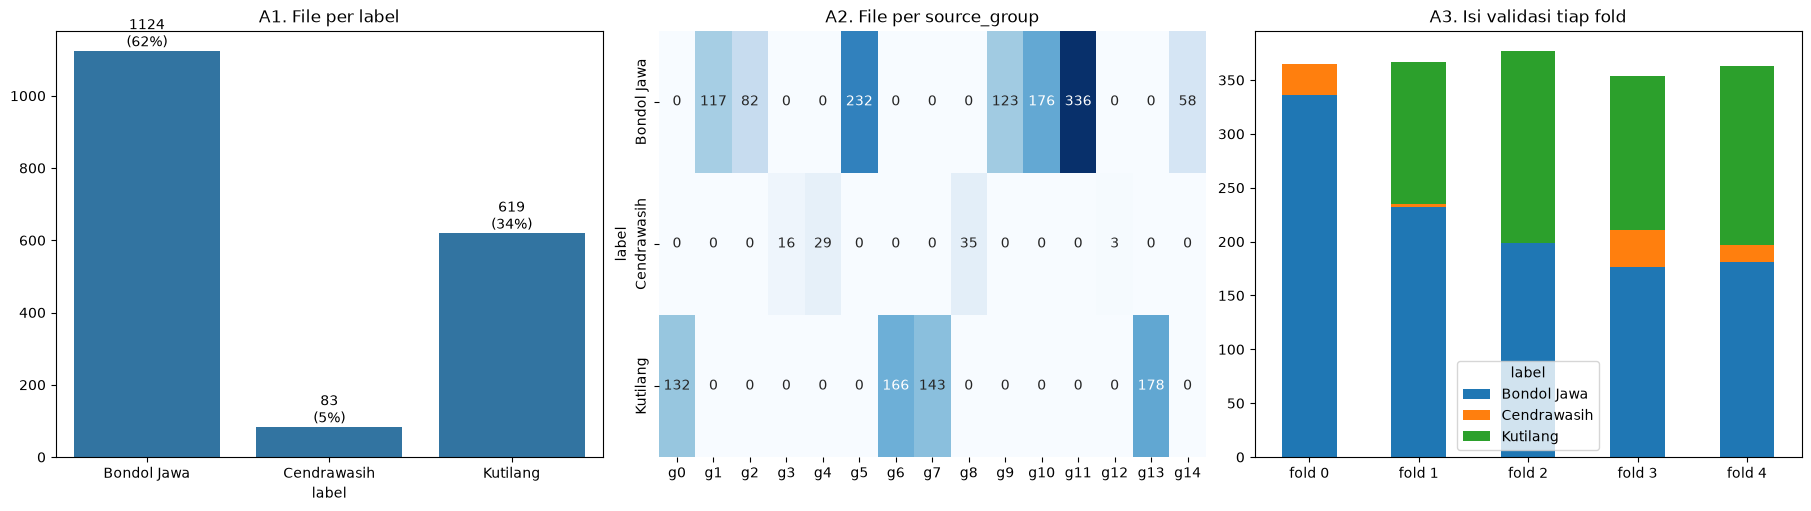

{0: '0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9e5a99d56c81c8bb09b', 1: '100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9', 2: '347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5', 3: '660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb', 4: '6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107', 5: '6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7', 6: '81213a446c8b0bbeb4746c7ef40a25f2c28db396267d00bb37901ec3b1ceba6a', 7: '81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19a85b167f462b833bae', 8: '8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3', 9: '90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6a3748c8d1355549406', 10: 'c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d20fb547bb5a2218c9b', 11: 'd20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7b978a1c8096c6a89eb', 12: 'd7bc3d5bed71ea4c9ab146301ba34f872cb0c68e681ff3cb23328687db112fda', 13: 'e6af0468065784bb1d6458c2d725d3c40a377f47131365ef8cfc3c20f88b6956', 1

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

metas = pd.read_csv(CFG["train_csv"])
metas['source_group'].nunique()
fig, ax = plt.subplots(1, 3, figsize=(18, 5), layout="constrained")   # ganti tight_layout
train = metas.copy()

# Helper: 5 angka baseline kamu dalam satu fungsi
def ringkas(s, bins=30):
    s = pd.Series(s).dropna()
    h, e = np.histogram(s, bins=bins)
    mode = (e[h.argmax()] + e[h.argmax() + 1]) / 2   # puncak histogram
    return pd.Series({"mean": s.mean(), "median": s.median(), "mode": mode,
                      "CV": s.std() / s.mean(), "skew": skew(s)})

# Helper: histogram + garis mean/median/mode, CV & skew di judul
def hist_stat(s, judul, ax):
    st = ringkas(s)
    sns.histplot(s, kde=True, bins=30, ax=ax, color="steelblue")
    for nama, warna in [("mean", "red"), ("median", "green"), ("mode", "orange")]:
        ax.axvline(st[nama], color=warna, ls="--", label=f"{nama} {st[nama]:.2f}")
    ax.set_title(f"{judul}\nCV={st['CV']:.2f} | skew={st['skew']:.2f}")
    ax.legend()

# Helper: tabel 5 angka per kelas
def tabel_stat(df, kolom):
    return df.groupby("label")[kolom].apply(ringkas).unstack().round(2)

y = train["label"].map({c: i for i, c in enumerate(order)}).values     # label -> angka, sejajar dengan train

# A1: value_counts -> bar + jumlah & persen
vc = train["label"].value_counts().reindex(order)
sns.barplot(x=vc.index, y=vc.values, ax=ax[0], order=order)
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f"{v}\n({v/len(train):.0%})", ha="center", va="bottom")
ax[0].set_title("A1. File per label")

# A2: berapa file tiap label per source_group (nama dipendekkan jadi g0, g1, ...)
ct = pd.crosstab(train["label"], train["source_group"]).reindex(order)
peta_group = dict(enumerate(ct.columns))      # simpan: g-nomor -> nama asli
ct.columns = [f"g{i}" for i in range(ct.shape[1])]
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("A2. File per source_group")

# A3: isi validasi tiap fold (split yang sama dengan skripmu)
cv = StratifiedGroupKFold(n_splits=CFG["n_folds"], shuffle=True, random_state=CFG["seed"])
rows = []
for k, (_, va) in enumerate(cv.split(np.zeros(len(train)), y, train["source_group"])):
    rows.append(train.iloc[va]["label"].value_counts().reindex(order).fillna(0).rename(f"fold {k}"))
pd.DataFrame(rows).plot(kind="bar", stacked=True, ax=ax[2])
ax[2].tick_params(axis="x", rotation=0)
ax[2].set_title("A3. Isi validasi tiap fold")

plt.show()                                     # tanpa tight_layout
print(peta_group)                              # cek g0, g1, ... itu source_group yang mana

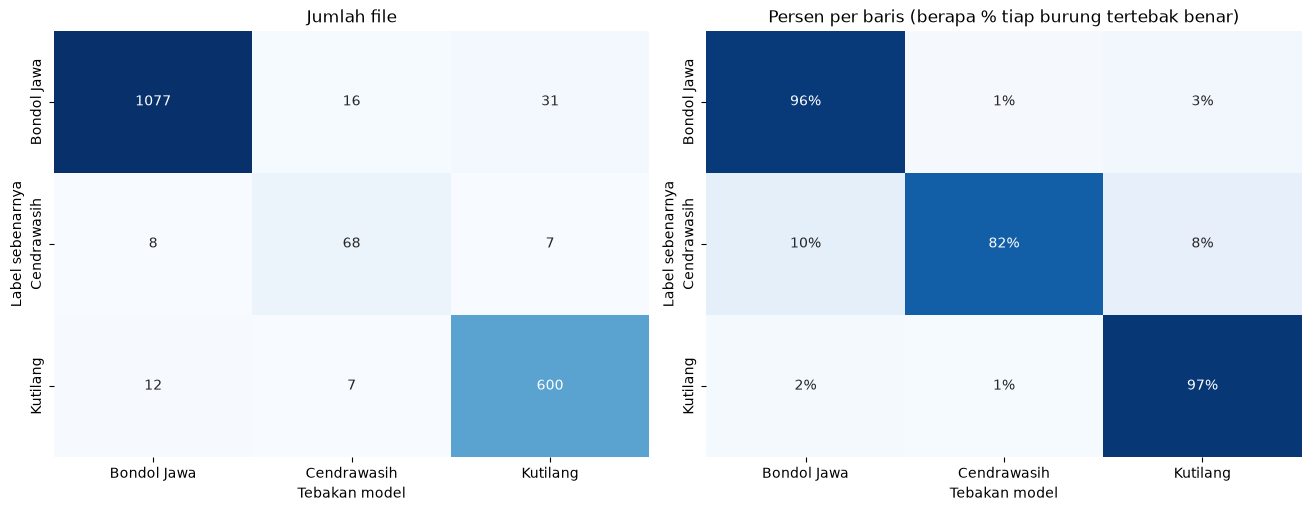

              precision    recall  f1-score   support

 Bondol Jawa       0.98      0.96      0.97      1124
 Cendrawasih       0.75      0.82      0.78        83
    Kutilang       0.94      0.97      0.95       619

    accuracy                           0.96      1826
   macro avg       0.89      0.92      0.90      1826
weighted avg       0.96      0.96      0.96      1826



In [12]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

X = np.nan_to_num(np.load("feat_train_v5_upgrade.npy"))      # cache fitur dari skripmu
assert X.shape[0] == len(train), "baris X tidak sama dengan metadata"

model = ExtraTreesClassifier(**BEST_PARAMS, random_state=CFG["seed"], n_jobs=-1)
pred_cv = cross_val_predict(model, X, y, groups=train["source_group"], cv=cv, n_jobs=1)

cm = confusion_matrix(y, pred_cv)                          # angka asli
cm_row = confusion_matrix(y, pred_cv, normalize="true")    # persen per baris

fig, ax = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=order, yticklabels=order, ax=ax[0])
ax[0].set_title("Jumlah file")
sns.heatmap(cm_row, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=order, yticklabels=order, ax=ax[1])
ax[1].set_title("Persen per baris (berapa % tiap burung tertebak benar)")
for a in ax:
    a.set_xlabel("Tebakan model"); a.set_ylabel("Label sebenarnya")
plt.show()
print(classification_report(y, pred_cv, target_names=order, zero_division=0))

              precision    recall  f1-score   support

 Bondol Jawa       0.98      0.96      0.97      1124
 Cendrawasih       0.75      0.82      0.78        83
    Kutilang       0.94      0.97      0.95       619

    accuracy                           0.96      1826
   macro avg       0.89      0.92      0.90      1826
weighted avg       0.96      0.96      0.96      1826

